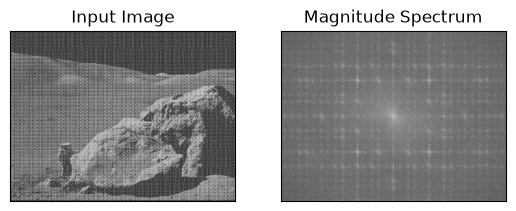

In [2]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [3]:
#Filter creating
# Low pass filter
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

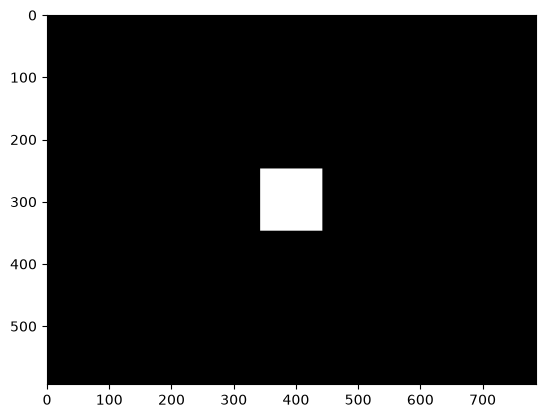

In [4]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [5]:
# Filtering
dft_shift = dft_shift*mask

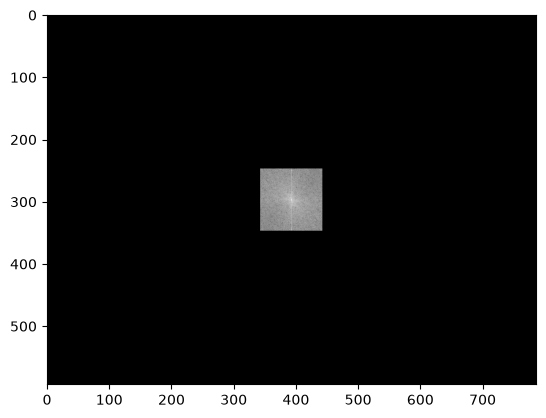

In [6]:
filtering_magn_res = 20*np.log1p(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')

In [7]:
#fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

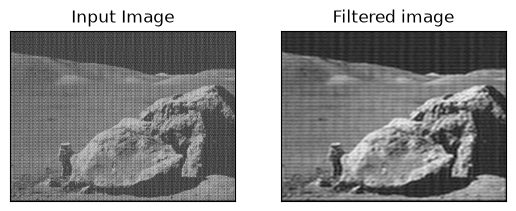

In [8]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

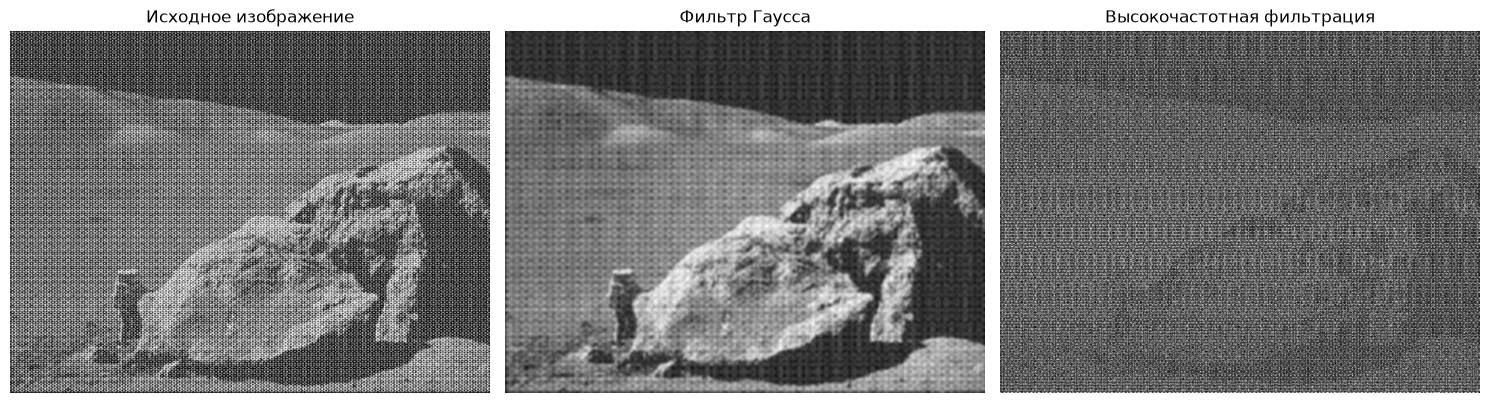

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError('Файл periodic_noise.JPG не найден')

gaussian = cv2.GaussianBlur(img, (9, 9), 2)

# было вычитание размытого изображения из исходного (img - gaussian), получая просто контуры.
#high_pass = img.astype(np.float32) - gaussian.astype(np.float32) было
# Нужна фильтрацию на основе ядра Гаусса: 
kernel_hp = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
high_pass = cv2.filter2D(img.astype(np.float32), -1, kernel_hp)


high_pass_abs = np.abs(high_pass)
max_value = np.percentile(high_pass_abs, 99)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(gaussian, cmap='gray')
axes[1].set_title('Фильтр Гаусса')

axes[2].imshow(
    high_pass_abs,
    cmap='gray',
    vmin=0,
    vmax=max(max_value, 1)
)
axes[2].set_title('Высокочастотная фильтрация')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

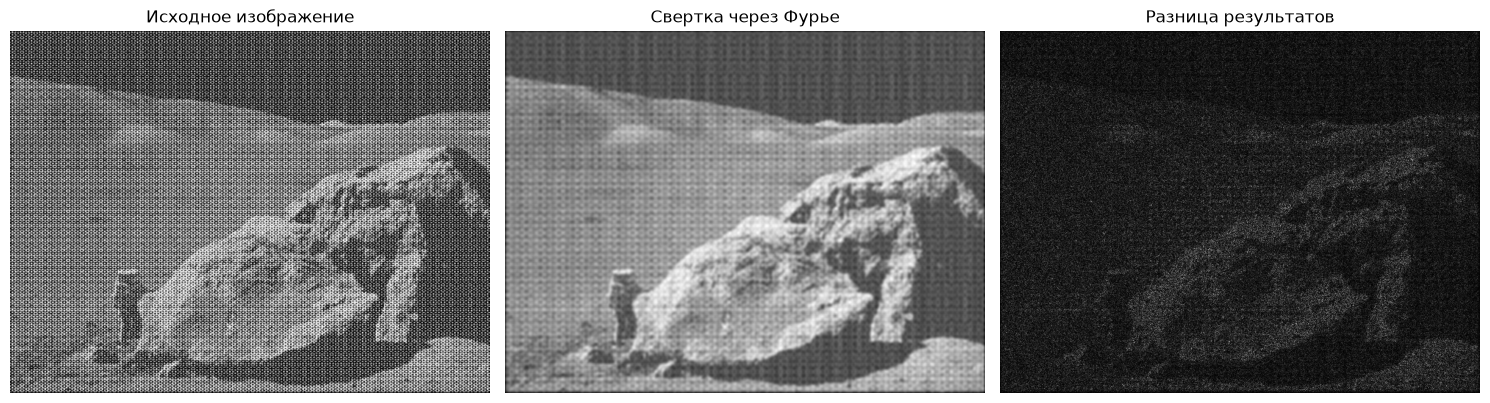

Максимальная разница: 0.00010461384601967438


In [11]:
# 1. Создаем ядро Гаусса (2D)
kernel_1d = cv2.getGaussianKernel(9, 2)
kernel_2d = np.outer(kernel_1d, kernel_1d)

# 2. Пространственная свертка (эталон)
spatial_result = cv2.filter2D(img.astype(np.float32), -1, kernel_2d, borderType=cv2.BORDER_CONSTANT)

# 3. Свертка через Фурье
h, w = img.shape
kh, kw = kernel_2d.shape

# ччтобы FFT работал корректно (без артефактов на краях), нужно дополнить изображение и ядро нулями до общего размера
# Размер должен быть h + kh - 1 и w + kw - 1
fft_shape = (h + kh - 1, w + kw - 1)

# Делаем FFT изображения и ядра
image_fft = np.fft.fft2(img.astype(np.float32), s=fft_shape)
kernel_fft = np.fft.fft2(kernel_2d, s=fft_shape)

# Перемножаем спектры (это и есть свертка в частотной области)
result_fft_full = np.fft.ifft2(image_fft * kernel_fft)

# Берем реальную часть (убираем мнимую, которая должна быть ~0)
result_fft = np.real(result_fft_full)

# Обрезаем результат до исходного размера изображения (т.к. мы дополняли нулями)
# Нам нужна центральная часть
result_fft = result_fft[kh//2 : kh//2 + h, kw//2 : kw//2 + w]

# 4. Считаем разницу
difference = np.abs(spatial_result - result_fft)
max_diff = np.max(difference)
#Вывод
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(result_fft, cmap='gray')
axes[1].set_title('Свертка через Фурье')

axes[2].imshow(difference, cmap='gray')
axes[2].set_title('Разница результатов')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f'Максимальная разница: {max_diff}')
#В старом коде был result_fft = np.fft.fft2(...) и попытки вывести это на экран. Но fft2 возвращает комплексные числа. matplotlib не умеет рисовать комплексные числа, поэтому он рисовал черный экран.
#В новом коде мы делаем np.fft.ifft2 (обратное преобразование) и берем np.real() 

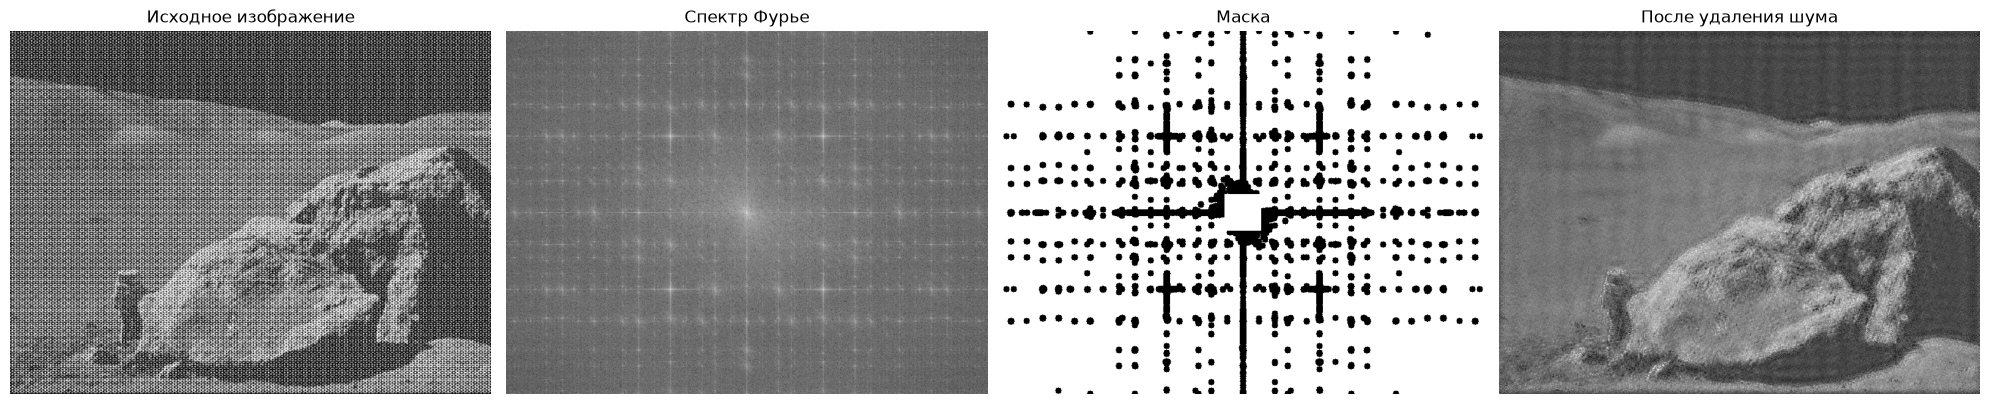

In [21]:
#Ошибка: поиск пиков шума через cv2.dilate (расширение). Эта функция ищет локальные минимумы (темные пятна),
#а нужны были локальные максимумы (яркие пятна шума). 
#Из-за этого программа не находила шум
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)

f = np.fft.fft2(img.astype(np.float32))
fshift = np.fft.fftshift(f)

# 1. Считаем спектр (добавляем +1 для защиты от нулей)
magnitude = np.log(1 + np.abs(fshift))
rows, cols = img.shape
cy, cx = rows // 2, cols // 2

# 2. Копируем спектр и зануляем центр (чтобы не трогать основную яркость картинки)
mag_no_center = magnitude.copy()
mag_no_center[cy-30:cy+30, cx-30:cx+30] = 0

# 3. Находим ПОРОГ. Берем самый высокий процентиль.
# Если маска черная, пробуйте понижать (99.5 -> 99.0 -> 98.0), пока не найдется шум.
threshold = np.percentile(mag_no_center, 99.2) 

# 4. Находим ВСЕ точки, которые ярче порога
# (Это проще и надежнее, чем искать локальные максимумы через erode)
ys, xs = np.where(mag_no_center > threshold)

# 5. Создаем маску (везде 1 - пропускаем)
mask = np.ones((rows, cols), dtype=np.float32)

# 6. Вырезаем найденные точки (рисуем черные круги)
for y, x in zip(ys, xs):
    cv2.circle(mask, (int(x), int(y)), 5, 0, -1) # Радиус 5

# Возвращаем центр (чтобы не упала яркость)
mask[cy-30:cy+30, cx-30:cx+30] = 1

# Применяем маску 
filtered_fft = fshift * mask
filtered = np.fft.ifft2(np.fft.ifftshift(filtered_fft))
filtered = np.abs(filtered)
filtered = np.clip(filtered, 0, 255).astype(np.uint8)

# Визуализация 
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(magnitude, cmap='gray')
axes[1].set_title('Спектр Фурье')

axes[2].imshow(mask, cmap='gray')
axes[2].set_title('Маска')

axes[3].imshow(filtered, cmap='gray')
axes[3].set_title('После удаления шума')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()